<a href="https://colab.research.google.com/github/SergeyVaganov/Lessons_NumPy_Pandas/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22FinalTest_VLAD_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Итоговое тестирование

Загрузите файл `salary_fix.csv`.

Кодировка: `CP1251`, разделители: `«;»`.

В файле представлены данные о заработной плате профессорско-преподавательского состава университета:

|Поле|Содержание|
|:-|:-|
|`'Т/Н'`|табельный номер, уникальный идентификатор работника
|`'Должность'`|должность работника (одна из занимаемых должностей)
|`'Ставка'`|часть ставки, на которую заключен трудовой договор по данной должности в данном подразделении
|`'Оклад (основной)'`|
|`'Оклад (совместительство)'`|
|`'Почасовая оплата'`|Сумма почасовой оплаты труда (обычно сверх оклада)
|`'Итого'`|общая сумма заработной платы

Обратите внимание, сотрудники идентифицируются по табельному номеру, на некоторых работников есть несколько записей – у них есть внутреннее совместительство.

Существуют сотрудники, у которых есть зарплата только по основному месту работы, есть основное и внутреннее совместительство - это штатные сотрудники. Есть внешние совместители – у них нет оклада по основному месту работы в данной организации.

Необходимо написать программу на Python с использованием модулей `Pandas` и `Pyplot`, которая позволяет получить аналитику данных.

In [368]:
import pandas as pd
import matplotlib.pyplot as plt

In [369]:
from google.colab import drive
import os
drive.mount('/content/gdrive', force_remount=True)
data_dir = '/content/gdrive/MyDrive/Colab Notebooks'
os.chdir(data_dir)

Mounted at /content/gdrive


In [370]:
df = pd.read_csv("salary_fix.csv", encoding='CP1251', delimiter=';')
columns_df = df.columns

In [371]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 899 entries, 0 to 898
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   ТН                        899 non-null    int64 
 1   Должность                 899 non-null    object
 2   Ставка                    899 non-null    object
 3   Оклад (основной)          686 non-null    object
 4   Оклад (совместительство)  661 non-null    object
 5   Почасовая оплата          222 non-null    object
 6   Итого                     899 non-null    object
dtypes: int64(1), object(6)
memory usage: 49.3+ KB


In [372]:
for column in columns_df[2:7]:
    df[column] = df[column].astype(str).str.replace(',','.')
    df[column] = pd.to_numeric(df[column], errors='coerce')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 899 entries, 0 to 898
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ТН                        899 non-null    int64  
 1   Должность                 899 non-null    object 
 2   Ставка                    899 non-null    float64
 3   Оклад (основной)          686 non-null    float64
 4   Оклад (совместительство)  661 non-null    float64
 5   Почасовая оплата          222 non-null    float64
 6   Итого                     899 non-null    float64
dtypes: float64(5), int64(1), object(1)
memory usage: 49.3+ KB


In [373]:
# df с сотрудниками по основному месту работы (с Оклад (основной))
basic_not_null = df.loc[df['Оклад (основной)'].notna()]
basic_not_null.head(5)

,ТН,Должность,Ставка,Оклад (основной),Оклад (совместительство),Почасовая оплата,Итого
0,160697,Доцент,1.5,9830.0,4915.0,5284.76,21663.83
1,2226,Доцент,0.5,4915.0,NaN,NaN,7185.72
4,1139,Доцент,1.2,9830.0,1966.0,NaN,16231.29
5,303243,Ассистент,1.0,8019.0,NaN,3894.00,10245.18
6,303209,Профессор,1.5,9830.0,4915.0,NaN,23586.10


In [374]:
basic_not_null.describe()

,ТН,Ставка,Оклад (основной),Оклад (совместительство),Почасовая оплата,Итого
count,686.000000,686.000000,686.000000,448.000000,215.000000,686.000000
mean,147563.443149,1.098032,7706.686851,3528.324598,5381.020000,14316.155729
std,134114.453550,0.399954,2269.874828,1335.671613,3011.420823,7063.310191
min,114.000000,0.100000,72.470000,36.230000,101.630000,896.530000
25%,2303.000000,1.000000,6098.160000,2545.265000,3252.160000,8965.240000
50%,105263.500000,1.100000,8623.000000,4009.500000,4878.240000,13536.215000
75%,302602.500000,1.500000,9830.000000,4311.500000,6479.175000,19401.480000
max,303576.000000,1.500000,11065.000000,5230.500000,20758.140000,42974.950000


In [375]:
# df с сотрудниками совместителями (без Оклад (основной))
basic_null = df.loc[df['Оклад (основной)'].isnull()]
basic_null.head(5)

,ТН,Должность,Ставка,Оклад (основной),Оклад (совместительство),Почасовая оплата,Итого
2,302429,Доцент,0.05,NaN,491.5,NaN,534.51
3,302429,Доцент,0.45,NaN,4423.5,NaN,4810.56
8,74317,Доцент,0.50,NaN,4915.0,NaN,7185.74
11,527,Доцент,0.25,NaN,2457.5,NaN,3592.87
18,2107,Профессор,0.50,NaN,5230.5,NaN,8456.68


In [376]:
basic_null.describe()

,ТН,Ставка,Оклад (основной),Оклад (совместительство),Почасовая оплата,Итого
count,213.000000,213.000000,0.0,213.000000,7.000000,213.000000
mean,161783.154930,0.342488,NaN,3055.622441,5675.520000,4033.178826
std,135636.980731,0.140215,NaN,1353.270014,3177.586848,2312.413096
min,256.000000,0.050000,NaN,346.940000,973.500000,448.270000
25%,4319.000000,0.250000,NaN,2004.750000,4278.625000,2267.380000
50%,164665.000000,0.300000,NaN,2891.180000,4543.000000,3707.900000
75%,302823.000000,0.500000,NaN,4311.500000,7392.070000,5030.020000
max,303606.000000,0.500000,NaN,5230.500000,10870.750000,13202.410000


1. (1 балл) Выведите Фонд оплаты труда(ФОТ):

a) всей организации (`r1a`)

b) в разрезе должностей (`r1b`)

c) ФОТ организации без учёта внешних совместителей (`r1c`)

d) ФОТ внешних совместителей (`r1d`).

In [377]:
r1a = df['Итого'].sum()
print('ФОТ всей организации:', r1a)

ФОТ всей организации: 10679949.92


In [378]:
r1b = df.groupby('Должность').agg({'Итого':['sum']})
print('ФОТ в разрезе должностей \n',r1b)

ФОТ в разрезе должностей 
                             Итого
                              sum
Должность                        
Ассистент              1034563.40
Доцент                 5271273.01
Преподаватель           452619.67
Профессор              1440885.75
Старший преподаватель  2480608.09


In [379]:
r1c = basic_not_null['Итого'].sum()
print('ФОТ организации без учёта внешних совместителей', r1c)

ФОТ организации без учёта внешних совместителей 9820882.83


In [380]:
r1d =  basic_null['Итого'].sum().round(2)
print('ФОТ внешних совместителей', r1d)

ФОТ внешних совместителей 859067.09


2. (1 балл) Выведите данные о структуре персонала по должностям и ставкам и постройте круговую диаграмму


In [381]:
def  Pie(values, labels, legend, title):
  explode = [0.01 for _ in values]
  plt.pie(values, labels=labels, autopct='%1.0f%%', explode=explode)
  plt.title(title)
  plt.legend(bbox_to_anchor=(1.5, 0.4, 0.5, 0.5), labels=legend)
  plt.show()

In [382]:
df_struct = df.groupby(['Должность'], sort=False)['ТН'].count().reset_index()
df_struct.columns = ['Должность', 'Кол-во сотрудников']
labels = df_struct['Должность'].values
values = df_struct['Кол-во сотрудников'].values
df_struct['legend'] = df_struct['Должность']+ ' - ' + df_struct['Кол-во сотрудников'].astype(str) + ' чел.'
legend = df_struct['legend']

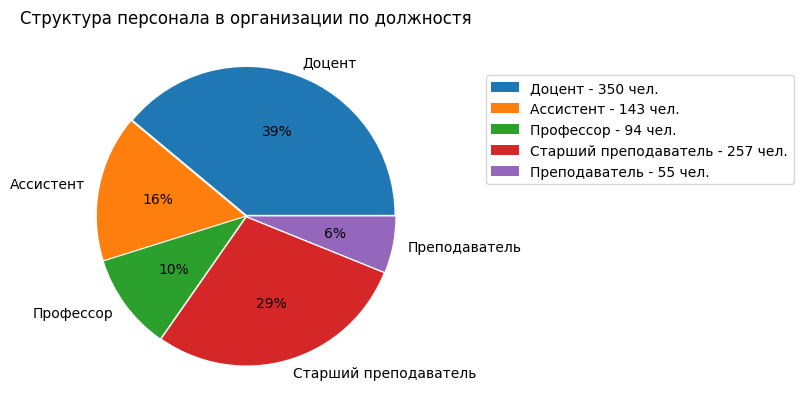

In [383]:
Pie(values, labels, legend, 'Структура персонала в организации по должностя')

In [384]:
df_struct = df.groupby(['Ставка'], sort=False)['ТН'].count().reset_index()
df_struct.columns = ['Ставка', 'Кол-во сотрудников']

bins = [0, 0.25, 0.5, 0.75, 1, 1.25, 1.5]
df_struct['Диапазон ставок'] = pd.cut(df_struct['Ставка'], bins)
df_struct_bins = df_struct.groupby(['Диапазон ставок'], observed=False).agg({'Кол-во сотрудников':'sum'}).reset_index()
df_struct_bins['legend'] = 'Ставки ' + df_struct['Диапазон ставок'].astype(str)+ ' - ' + df_struct['Кол-во сотрудников'].astype(str) + ' чел.'

labels = df_struct_bins['Диапазон ставок'].values.astype(str)
values = df_struct_bins['Кол-во сотрудников'].values
legend = df_struct_bins['legend']

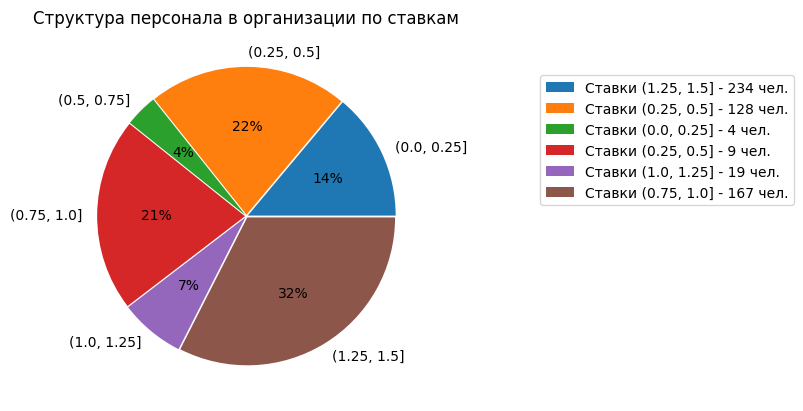

In [385]:
Pie(values, labels, legend, 'Структура персонала в организации по ставкам')

3. (1 балл) Проанализируйте заработную плату ассистентов:
    
- выведите минимальную (`r3a`)
- среднюю (`r3b`)
- максимальную заработную плату (`r3c`)

по этой категории

In [386]:
assistents = df.loc[df['Должность'] == 'Ассистент']

result = assistents.agg( min=('Итого', 'min'),
                        mean=('Итого', 'mean'),
                        max=('Итого', 'max'),
                        ).round(2).reset_index()
r3a = result['Итого'][0]
r3b = result['Итого'][1]
r3c = result['Итого'][2]

print(' Минимальная зарплата ассистентов',r3a,'\n',
      'Средняя зарплата ассистентов', r3b,'\n',
      'Максимальная зарплата ассистентов',r3c)

 Минимальная зарплата ассистентов 1046.48 
 Средняя зарплата ассистентов 7234.71 
 Максимальная зарплата ассистентов 20019.5


4. (1 балл) Проанализируйте доцентов-внешних совместителей. Выведите таблицу с их группировкой по табельному номеру, представьте в таблице общую величину ставки и сумму заработной платы (DataFrame `r4a` с `columns=['Ставка', 'Итого']`).

Выведите их численность с учётом группировки – `r4b`.

In [387]:
basic_null_group = basic_null.groupby(['ТН','Должность']).agg({'Ставка':'sum', 'Итого':'sum'}).reset_index()
basic_null_group_docent = basic_null_group.loc[basic_null_group['Должность']=='Доцент'].reset_index()

In [388]:
r4a = basic_null_group_docent[['Ставка', 'Итого']]
print(r4a.head(5))

   Ставка    Итого
0    0.25  3592.87
1    0.10  1352.61
2    0.15  2180.79
3    0.40  5580.12
4    0.20  2874.29


In [389]:
r4b = r4a.shape[0]
print('Численность доцентов с учётом группировки:',r4b, 'чел.')

Численность доцентов с учётом группировки: 66 чел.


5. (1 балл) Проанализируйте заработную плату работников (с учётом совместительства), работающих в данной организации по основному месту работы. Выведите минимальную (`r5a`), среднюю (`r5b`) и максимальную заработную плату (`r5c`) по этой категории.

In [390]:
result = basic_not_null.agg( min=('Итого', 'min'),
                        mean=('Итого', 'mean'),
                        max=('Итого', 'max'),
                        ).round(2).reset_index()
r5a = result['Итого'][0]
r5b = result['Итого'][1]
r5c = result['Итого'][2]

print(' Минимальная зарплата основных работников',r5a,'\n',
      'Средняя зарплата основных работников', r5b,'\n',
      'Максимальная зарплата основных работников',r5c)

 Минимальная зарплата основных работников 896.53 
 Средняя зарплата основных работников 14316.16 
 Максимальная зарплата основных работников 42974.95


6. (1 балл) Проведите анализ ставок внешних совместителей: выведите минимальную (`r6a`), среднюю (`r6b`) и максимальную ставку (`r6c`) по этой категории.

In [391]:
result = basic_null.agg( min=('Итого', 'min'),
                        mean=('Итого', 'mean'),
                        max=('Итого', 'max'),
                        ).round(2).reset_index()
r6a = result['Итого'][0]
r6b = result['Итого'][1]
r6c = result['Итого'][2]

print(' Минимальная зарплата совместителей',r6a,'\n',
      'Средняя зарплата совместителей', r6b,'\n',
      'Максимальная зарплата совместителей',r6c)

 Минимальная зарплата совместителей 448.27 
 Средняя зарплата совместителей 4033.18 
 Максимальная зарплата совместителей 13202.41


7. (1 балл) Выведите список табельных номеров доцентов, работающих на 1,0 ставку (`r7a`)

In [392]:
docent_rate_1 = df.loc[((df['Ставка']==1) & (df['Должность']=='Доцент'))]
r7a = docent_rate_1['ТН'].unique()
print('Cписок табельных номеров доцентов, работающих на ставку = 1,0:  \n',r7a)

Cписок табельных номеров доцентов, работающих на ставку = 1,0:  
 [ 74317   1651    540   2328   1204 103707  73454 165021    114    577
  70812   2937 165283  74763 300848   1576   2327 160954 105887   1504
   2383   1250 100364  74332   4544   3027   5703 167182   2257 164775
 160830   2774   2403   2012   5230   2263   2293   2454 302474   1595
 103197    585   1616 141369 155716  70766 106038  74326 161208 303567
 103087]


8. (1 балл) Найдите самых незагруженных по основному месту работы сотрудников и выведите их табельные номера и ставку (`r8a`).

In [393]:
basic_not_null_sorted = basic_not_null.sort_values('Ставка').reset_index().head(10)
r8a = basic_not_null_sorted[['ТН', 'Ставка']]
print('Cамые незагруженные по основному месту работы сотрудники: \n',r8a)

Cамые незагруженные по основному месту работы сотрудники: 
        ТН  Ставка
0     583    0.10
1    8593    0.10
2  301469    0.10
3   70032    0.10
4    2018    0.10
5    2838    0.15
6    1602    0.15
7  160974    0.15
8  303534    0.15
9  302723    0.15


9. (2 балла) Постройте графики формирования ФОТ от меньших зарплат к большим для:

а) всей организации;

б) работников, чьё основное место работы находится в организации (с учётом внутреннего совместительства);

в) внешних совместителей.


In [394]:
fot = df['Итого'].sum()

In [395]:
def Hist(fot, df, bins, title):
  _, bin_edges = pd.cut(df['Итого'], bins=bins, retbins=True)
  plt.hist(df['Итого'], weights=df['Итого']/fot, bins=bins, edgecolor='w', color = 'b', linewidth=3)
  plt.title(title)
  plt.ylabel('%')
  plt.xlabel('Диапазон зарплат')
  plt.xticks(bin_edges, rotation=45)
  plt.show()


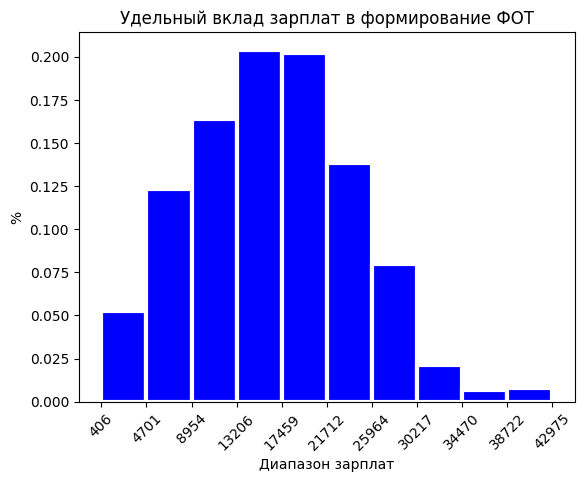

In [396]:
Hist(fot, df, 10, 'Удельный вклад зарплат в формирование ФОТ')

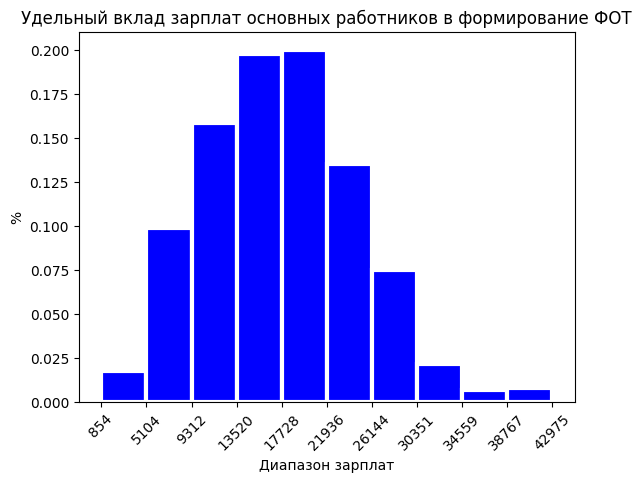

In [397]:
Hist(fot, basic_not_null, 10, 'Удельный вклад зарплат основных работников в формирование ФОТ')

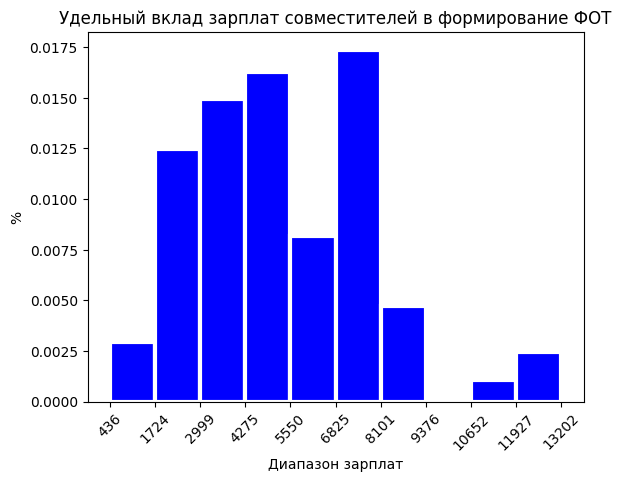

In [398]:
Hist(fot, basic_null, 10, 'Удельный вклад зарплат совместителей в формирование ФОТ')